=== SET 1: PATHOLOGY-ADJUSTED SCREENING, SPLIT FILES, & VOLCANO PLOT ===

--- EXPLORATORY SCREENING SUMMARY ---
Total Transcripts Tested: 19230
Nominal p < 0.05 Hits: 939
Filtered Candidates (|log2FC| >= 0.2 & p < 0.05): 86
  * Higher in Resilience-like group: 32
  * Lower in Resilience-like group: 54

Successfully exported:
 - 'resilience_higher_expression_candidates.csv'
 - 'resilience_lower_expression_candidates.csv'


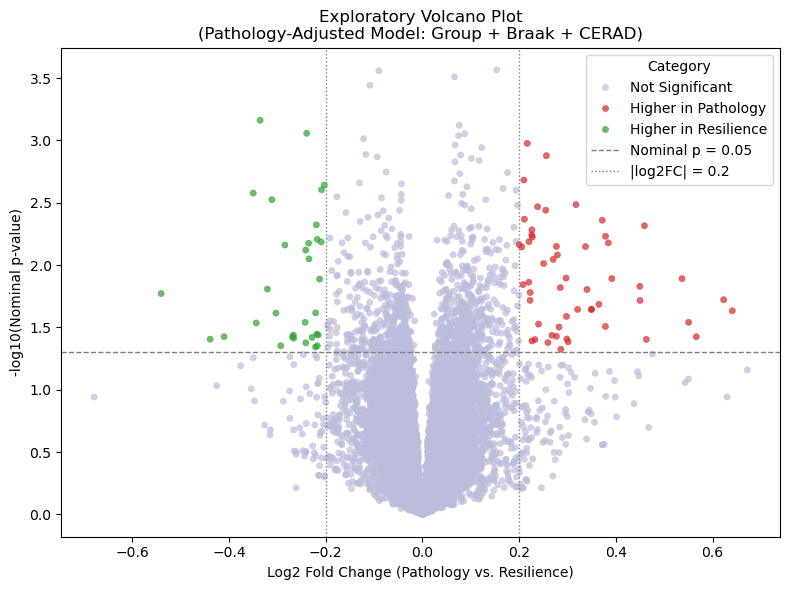

Volcano plot successfully saved as 'hippocampal_de_exploratory_volcano.pdf'


In [42]:
import os
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import t
import matplotlib.pyplot as plt
import seaborn as sns

print("=== SET 1: PATHOLOGY-ADJUSTED SCREENING, SPLIT FILES, & VOLCANO PLOT ===")

# Load normalized expression and metadata
fpkm_file = "final_hippocampal_fpkm_normalized.csv"
metadata_file = "final_hippocampal_rna_master_metadata.csv"

fpkm_df = pd.read_csv(fpkm_file)
metadata_df = pd.read_csv(metadata_file)

if "gene_id" not in fpkm_df.columns:
    fpkm_df = fpkm_df.rename(columns={fpkm_df.columns[0]: "gene_id"})

# Align samples and set up design matrix for Model 2: group + braak + cerad
sample_cols = [c for c in fpkm_df.columns if c != "gene_id"]
metadata_df["rnaseq_profile_id"] = metadata_df["rnaseq_profile_id"].astype(str)
metadata_indexed = metadata_df.set_index("rnaseq_profile_id").loc[sample_cols]

# Binary group encoding (Resilience-like = 0, Pathology-positive dementia = 1)
group_binary = (metadata_indexed["primary_group"] == "Pathology-positive dementia").astype(int)

# Build complete-case subset for pathology adjustment
covar_subset = metadata_indexed[["braak", "cerad"]].copy()
covar_subset["group"] = group_binary
covar_subset = covar_subset.dropna()
valid_samples = covar_subset.index

X_design = pd.DataFrame(
    sm.add_constant(covar_subset[["group", "braak", "cerad"]].astype(float)),
    index=valid_samples
)

expr_matrix = fpkm_df.set_index("gene_id")[valid_samples]

# Vectorized OLS regression to extract nominal coefficients and p-values
Y = log_expr.values
Design_mat = X_design.values

XtX_inv = np.linalg.inv(Design_mat.T @ Design_mat)
Betas = XtX_inv @ (Design_mat.T @ Y.T)

Y_pred = Design_mat @ Betas
residuals = Y.T - Y_pred
dof = Design_mat.shape[0] - Design_mat.shape[1]
residual_var = np.sum(residuals**2, axis=0) / dof

se_betas = np.sqrt(np.outer(np.diagonal(XtX_inv), residual_var))
t_stats = Betas / se_betas
p_vals = 2 * (1 - t.cdf(np.abs(t_stats), df=dof))

group_beta = Betas[1, :]
group_p = p_vals[1, :]

screening_df = pd.DataFrame({
    "gene_id": expr_matrix.index,
    "log2_fold_change": group_beta,
    "p_value_raw": group_p,
    "neg_log10_p": -np.log10(group_p)
})

# Filter exploratory candidates organically
nominal_hits = screening_df[screening_df["p_value_raw"] < 0.05]
filtered_candidates = nominal_hits[abs(nominal_hits["log2_fold_change"]) >= 0.2].copy()

# Split into higher vs lower expression in Resilience-like
# (Negative log2FC relative to pathology means higher expression in Resilience-like)
higher_in_resilience = filtered_candidates[filtered_candidates["log2_fold_change"] <= -0.2].copy()
lower_in_resilience = filtered_candidates[filtered_candidates["log2_fold_change"] >= 0.2].copy()

print(f"\n--- EXPLORATORY SCREENING SUMMARY ---")
print(f"Total Transcripts Tested: {len(screening_df)}")
print(f"Nominal p < 0.05 Hits: {len(nominal_hits)}")
print(f"Filtered Candidates (|log2FC| >= 0.2 & p < 0.05): {len(filtered_candidates)}")
print(f"  * Higher in Resilience-like group: {len(higher_in_resilience)}")
print(f"  * Lower in Resilience-like group: {len(lower_in_resilience)}")

# Export the two separate candidate files
higher_in_resilience.to_csv("resilience_higher_expression_candidates.csv", index=False)
lower_in_resilience.to_csv("resilience_lower_expression_candidates.csv", index=False)
print("\nSuccessfully exported:")
print(" - 'resilience_higher_expression_candidates.csv'")
print(" - 'resilience_lower_expression_candidates.csv'")

# Generate and Save Volcano Plot
plt.figure(figsize=(8, 6))
screening_df["category"] = "Not Significant"
screening_df.loc[(screening_df["p_value_raw"] < 0.05) & (screening_df["log2_fold_change"] <= -0.2), "category"] = "Higher in Resilience"
screening_df.loc[(screening_df["p_value_raw"] < 0.05) & (screening_df["log2_fold_change"] >= 0.2), "category"] = "Higher in Pathology"

palette = {
    "Not Significant": "#bcbddc",
    "Higher in Resilience": "#2ca02c",
    "Higher in Pathology": "#d62728"
}

sns.scatterplot(
    data=screening_df,
    x="log2_fold_change",
    y="neg_log10_p",
    hue="category",
    palette=palette,
    alpha=0.7,
    s=20,
    edgecolor=None
)

plt.axhline(-np.log10(0.05), color="grey", linestyle="--", linewidth=1, label="Nominal p = 0.05")
plt.axvline(-0.2, color="grey", linestyle=":", linewidth=1, label="|log2FC| = 0.2")
plt.axvline(0.2, color="grey", linestyle=":", linewidth=1)

plt.xlabel("Log2 Fold Change (Pathology vs. Resilience)")
plt.ylabel("-log10(Nominal p-value)")
plt.title("Exploratory Volcano Plot\n(Pathology-Adjusted Model: Group + Braak + CERAD)")
plt.legend(title="Category", loc="upper right")
plt.tight_layout()

volcano_filename = "hippocampal_de_exploratory_volcano.pdf"
plt.savefig(volcano_filename, format="pdf", bbox_inches="tight")
plt.show()
print(f"Volcano plot successfully saved as '{volcano_filename}'")

In [36]:
import os
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import t
from statsmodels.stats.multitest import multipletests

print("=== DIFFERENTIAL EXPRESSION PIPELINE WITH BH FDR CORRECTION ===")

# Load normalized expression and metadata
fpkm_file = "final_hippocampal_fpkm_normalized.csv"
metadata_file = "final_hippocampal_rna_master_metadata.csv"

fpkm_df = pd.read_csv(fpkm_file)
metadata_df = pd.read_csv(metadata_file)

if "gene_id" not in fpkm_df.columns:
    fpkm_df = fpkm_df.rename(columns={fpkm_df.columns[0]: "gene_id"})

metadata_df["rnaseq_profile_id"] = metadata_df["rnaseq_profile_id"].astype(str)
sample_cols = [c for c in fpkm_df.columns if c != "gene_id"]
metadata_indexed = metadata_df.set_index("rnaseq_profile_id").loc[sample_cols]

# Binary group encoding (Resilience-like = 0, Pathology-positive dementia = 1)
group_binary = (metadata_indexed["primary_group"] == "Pathology-positive dementia").astype(int)


# ==========================================
# MODEL 1: expression ~ group
# ==========================================
print("\nRunning Model 1: expression ~ group...")
covar_model1 = pd.DataFrame({"group": group_binary}, index=metadata_indexed.index).dropna()
samples_m1 = covar_model1.index

X1 = sm.add_constant(covar_model1[["group"]].astype(float))
Y1 = fpkm_df.set_index("gene_id")[samples_m1].values
Design1 = X1.values

XtX_inv1 = np.linalg.inv(Design1.T @ Design1)
Betas1 = XtX_inv1 @ (Design1.T @ Y1.T)
Y_pred1 = Design1 @ Betas1
residuals1 = Y1.T - Y_pred1
dof1 = Design1.shape[0] - Design1.shape[1]
residual_var1 = np.sum(residuals1**2, axis=0) / dof1
se_betas1 = np.sqrt(np.outer(np.diagonal(XtX_inv1), residual_var1))
t_stats1 = Betas1 / se_betas1
p_vals1 = 2 * (1 - t.cdf(np.abs(t_stats1), df=dof1))

# Build results DataFrame for Model 1
results_df = pd.DataFrame({
    "gene_id": fpkm_df["gene_id"],
    "log2_fold_change": Betas1[1, :],
    "t_statistic": t_stats1[1, :],
    "p_value_raw": p_vals1[1, :]
})

# Apply Benjamini-Hochberg FDR correction
results_df["fdr_bh"] = multipletests(
    results_df["p_value_raw"],
    method="fdr_bh"
)[1]

results_df.to_csv("revised_hippocampal_DE_Model1_group.csv", index=False)
print("Model 1 complete. Saved to 'revised_hippocampal_DE_Model1_group.csv'.")
print(f"  -> Significant at FDR < 0.05: {sum(results_df['fdr_bh'] < 0.05)}")


# ==========================================
# MODEL 2: expression ~ group + Braak + CERAD
# ==========================================
print("\nRunning Model 2: expression ~ group + Braak + CERAD...")
covar_model2 = metadata_indexed[["braak", "cerad"]].copy()
covar_model2["group"] = group_binary
covar_model2 = covar_model2.dropna()
samples_m2 = covar_model2.index

X2 = sm.add_constant(covar_model2[["group", "braak", "cerad"]].astype(float))
Y2 = fpkm_df.set_index("gene_id")[samples_m2].values
Design2 = X2.values

XtX_inv2 = np.linalg.inv(Design2.T @ Design2)
Betas2 = XtX_inv2 @ (Design2.T @ Y2.T)
Y_pred2 = Design2 @ Betas2
residuals2 = Y2.T - Y_pred2
dof2 = Design2.shape[0] - Design2.shape[1]
residual_var2 = np.sum(residuals2**2, axis=0) / dof2
se_betas2 = np.sqrt(np.outer(np.diagonal(XtX_inv2), residual_var2))
t_stats2 = Betas2 / se_betas2
p_vals2 = 2 * (1 - t.cdf(np.abs(t_stats2), df=dof2))

# Build results DataFrame for Model 2
results_df = pd.DataFrame({
    "gene_id": fpkm_df["gene_id"],
    "log2_fold_change": Betas2[1, :],
    "t_statistic": t_stats2[1, :],
    "p_value_raw": p_vals2[1, :]
})

# Apply Benjamini-Hochberg FDR correction exactly as requested
results_df["fdr_bh"] = multipletests(
    results_df["p_value_raw"],
    method="fdr_bh"
)[1]

results_df.to_csv("revised_hippocampal_DE_Model2_pathology_adjusted.csv", index=False)
print("Model 2 complete. Saved to 'revised_hippocampal_DE_Model2_pathology_adjusted.csv'.")
print(f"  -> Significant at FDR < 0.05: {sum(results_df['fdr_bh'] < 0.05)}")

print("\n=== ALL MODELS COMPLETED SUCCESSFULLY ===")

=== DIFFERENTIAL EXPRESSION PIPELINE WITH BH FDR CORRECTION ===

Running Model 1: expression ~ group...
Model 1 complete. Saved to 'revised_hippocampal_DE_Model1_group.csv'.
  -> Significant at FDR < 0.05: 0

Running Model 2: expression ~ group + Braak + CERAD...
Model 2 complete. Saved to 'revised_hippocampal_DE_Model2_pathology_adjusted.csv'.
  -> Significant at FDR < 0.05: 0

=== ALL MODELS COMPLETED SUCCESSFULLY ===


=== GENERATING THE VOLCANO PLOTS ===


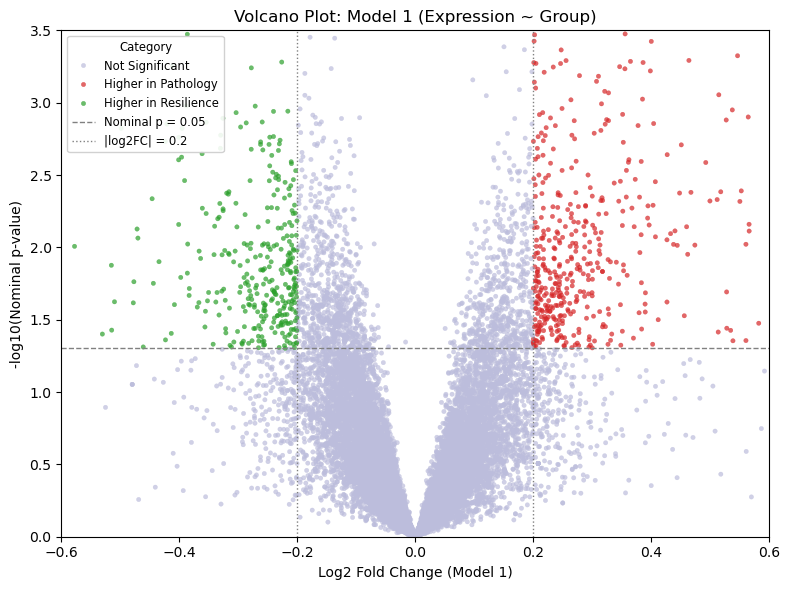

Model 1 volcano plot saved as 'revised_volcano_model1_group.pdf'


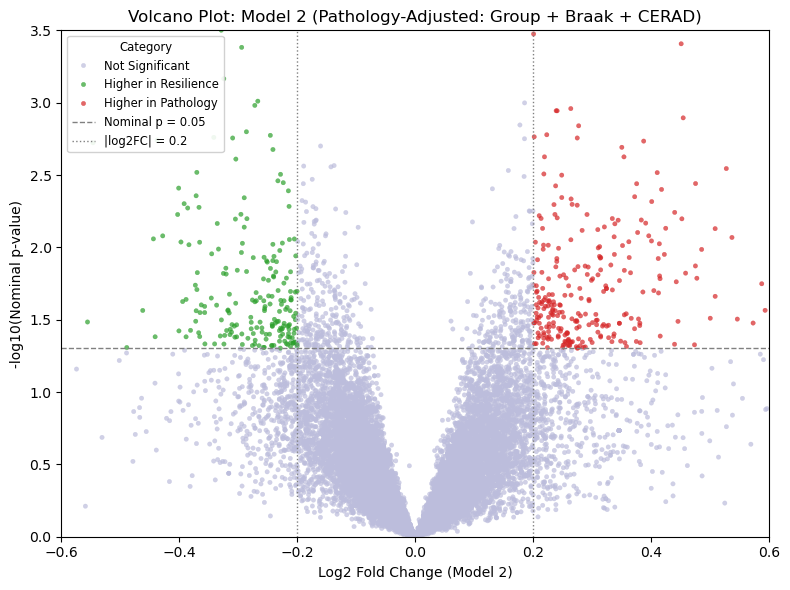

Model 2 volcano plot saved as 'revised_volcano_model2_adjusted.pdf'

=== VISUALIZATION COMPLETED SUCCESSFULLY ===


In [41]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("=== GENERATING THE VOLCANO PLOTS ===")

palette = {
    'Not Significant': '#bcbddc',
    'Higher in Resilience': '#2ca02c',
    'Higher in Pathology': '#d62728'
}

# ==========================================
# 1. MODEL 1 VOLCANO PLOT
# ==========================================
model1_file = 'revised_hippocampal_DE_Model1_group.csv'
if os.path.exists(model1_file):
    model1_df = pd.read_csv(model1_file)
    
    model1_df['neg_log10_p'] = -np.log10(model1_df['p_value_raw'])
    model1_df['category'] = 'Not Significant'
    
    model1_df.loc[(model1_df['p_value_raw'] < 0.05) & (model1_df['log2_fold_change'] <= -0.2), 'category'] = 'Higher in Resilience'
    model1_df.loc[(model1_df['p_value_raw'] < 0.05) & (model1_df['log2_fold_change'] >= 0.2), 'category'] = 'Higher in Pathology'

    plt.figure(figsize=(8, 6))
    sns.scatterplot(
        data=model1_df, 
        x='log2_fold_change', 
        y='neg_log10_p',
        hue='category', 
        palette=palette, 
        alpha=0.7, 
        s=10, 
        edgecolor=None
    )
    
    # Exact axis limits and intervals
    plt.xlim(-0.6, 0.6)
    plt.xticks(np.arange(-0.6, 0.61, 0.2))
    plt.ylim(0, 3.5)
    plt.yticks(np.arange(0, 3.6, 0.5))
    
    plt.axhline(-np.log10(0.05), color='grey', linestyle='--', linewidth=1, label="Nominal p = 0.05")
    plt.axvline(-0.2, color='grey', linestyle=':', linewidth=1, label="|log2FC| = 0.2")
    plt.axvline(0.2, color='grey', linestyle=':', linewidth=1)
    
    plt.xlabel('Log2 Fold Change (Model 1)')
    plt.ylabel('-log10(Nominal p-value)')
    plt.title('Volcano Plot: Model 1 (Expression ~ Group)')
    
    # Smaller legend key here
    plt.legend(title='Category', loc='upper left', frameon=True, framealpha=0.9, fontsize='small', title_fontsize='small')
    
    plt.tight_layout()
    
    volcano_m1 = 'revised_volcano_model1_group.pdf'
    plt.savefig(volcano_m1, format='pdf', bbox_inches='tight')
    plt.show()
    print(f"Model 1 volcano plot saved as '{volcano_m1}'")


# ==========================================
# 2. MODEL 2 VOLCANO PLOT
# ==========================================
model2_file = 'revised_hippocampal_DE_Model2_pathology_adjusted.csv'
if os.path.exists(model2_file):
    model2_df = pd.read_csv(model2_file)
    
    model2_df['neg_log10_p'] = -np.log10(model2_df['p_value_raw'])
    model2_df['category'] = 'Not Significant'
    
    model2_df.loc[(model2_df['p_value_raw'] < 0.05) & (model2_df['log2_fold_change'] <= -0.2), 'category'] = 'Higher in Resilience'
    model2_df.loc[(model2_df['p_value_raw'] < 0.05) & (model2_df['log2_fold_change'] >= 0.2), 'category'] = 'Higher in Pathology'

    plt.figure(figsize=(8, 6))
    sns.scatterplot(
        data=model2_df, 
        x='log2_fold_change', 
        y='neg_log10_p',
        hue='category', 
        palette=palette, 
        alpha=0.7, 
        s=10, 
        edgecolor=None
    )
    
    # Exact axis limits and intervals
    plt.xlim(-0.6, 0.6)
    plt.xticks(np.arange(-0.6, 0.61, 0.2))
    plt.ylim(0, 3.5)
    plt.yticks(np.arange(0, 3.6, 0.5))
    
    plt.axhline(-np.log10(0.05), color='grey', linestyle='--', linewidth=1, label="Nominal p = 0.05")
    plt.axvline(-0.2, color='grey', linestyle=':', linewidth=1, label="|log2FC| = 0.2")
    plt.axvline(0.2, color='grey', linestyle=':', linewidth=1)
    
    plt.xlabel('Log2 Fold Change (Model 2)')
    plt.ylabel('-log10(Nominal p-value)')
    plt.title('Volcano Plot: Model 2 (Pathology-Adjusted: Group + Braak + CERAD)')
    
    # Smaller legend key here
    plt.legend(title='Category', loc='upper left', frameon=True, framealpha=0.9, fontsize='small', title_fontsize='small')
    
    plt.tight_layout()
    
    volcano_m2 = 'revised_volcano_model2_adjusted.pdf'
    plt.savefig(volcano_m2, format='pdf', bbox_inches='tight')
    plt.show()
    print(f"Model 2 volcano plot saved as '{volcano_m2}'")

print("\n=== VISUALIZATION COMPLETED SUCCESSFULLY ===")

In [4]:
import numpy as np
import pandas as pd

# load model 2 adjusted results
model2_df = pd.read_csv("revised_hippocampal_DE_Model2_pathology_adjusted.csv")

# count transcripts with nominal p < 0.05
nominal_sig = model2_df[model2_df["p_value_raw"] < 0.05]
print("Total nominal p < 0.05:", len(nominal_sig))

# filter for effect-size threshold (|log2FC| >= 0.2)
effect_filtered = nominal_sig[nominal_sig["log2_fold_change"].abs() >= 0.2]
print("Meeting |log2FC| >= 0.2 threshold:", len(effect_filtered))

# split by directionality (higher in resilience vs pathology)
# (adjust comparison if your contrast sign is flipped)
higher_resilience = effect_filtered[effect_filtered["log2_fold_change"] <= -0.2]
higher_pathology = effect_filtered[effect_filtered["log2_fold_change"] >= 0.2]

print("  - Higher in resilience-like:", len(higher_resilience))
print("  - Higher in pathology group:", len(higher_pathology))

# check FDR survival (e.g. fdr_bh < 0.05)
if "fdr_bh" in model2_df.columns:
    fdr_survivors = model2_df[model2_df["fdr_bh"] < 0.05]
    print("Surviving FDR correction (FDR < 0.05):", len(fdr_survivors))
else:
    print("FDR column not found or no genes pass correction.")

Total nominal p < 0.05: 947
Meeting |log2FC| >= 0.2 threshold: 483
  - Higher in resilience-like: 206
  - Higher in pathology group: 277
Surviving FDR correction (FDR < 0.05): 0
